<a href="https://colab.research.google.com/github/Shaunblast/MNIST_CNN_Classifier/blob/main/MNIST_ConvolutionalNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import sklearn
import torch
import torch.nn as nn
import torch.nn.functional as nnf
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.utils import make_grid
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
%matplotlib inline



In [2]:
#Transform MNIST data from two dimension to 4 dimension tensor
transform = transforms.ToTensor()


In [3]:
# Import train data using the torchvision data in datasets
train_data = datasets.MNIST(root='/CNN_data', train=True, download=True, transform=transform)

# Import Test data the torchvision data in datasets
test_data = datasets.MNIST(root='/CNN_data', train=False, download=True, transform=transform)

100%|██████████| 9.91M/9.91M [00:00<00:00, 18.7MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 603kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 5.55MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 9.05MB/s]


In [4]:
# Load our data for train & test in small batches (intaking a set number of total images per run)
train_loader = DataLoader(train_data, batch_size=10, shuffle=True)

test_loader = DataLoader(test_data, batch_size=10, shuffle=False)

In [5]:
# Start by creating a class that will house the attributes and methods of the CNN model
class ConvolutionalNetwork(nn.Module):
  def __init__(self):
    super().__init__()

#Introduction of my convolutional layer that will take 1 image, output 8 features/channels, and have a kernel of size [3,3] with a stride of 1
    self.conv1 = nn.Conv2d(1, 8, 3, 1)

#Introduction of my 2nd convolutional layer that will take 8 features from conv1, output 24 features, and have a kernel of size [3,3] with a stride of 1

    self.conv2 = nn.Conv2d(8, 24, 3, 1)

#Introduce fully connected layers
##NOTE TO SELF: When doing convolution, there is a padding parameter, which is supposed to prevent pixels from being dropped when convolution occurs.
## Padding was not used, so 1 pixel is dropped on both length and width of image (so 2 pixels are lost total after each convolution)
##So after two convolutional layers and pooling layers that math to get to the pixel width/length of the image is ((28 - 2) / 2 - 2) / 2

#Fully connected layer that is taking 5*5*24 (5*5 = length/width, 24 = output features/channels) and flattening out to 180 neurons
##The "feature maps" are now the abstract traits being tracked of the image. So, there are now 24 channels for the tracking of output features.
    self.fc1 = nn.Linear(24*5*5, 180)

# Second layer of fully connected neurons (input = 180 neurons from last layer, output = neurons but a decrease)
    self.fc2 = nn.Linear(180, 90)

# Third layer of fully connected neurons (input = 90 neurons from last layer, output = 10 due to numbers being from 0 - 9 aka number of classes)
    self.fc3 = nn.Linear(90, 10)



# Now to make a forward function so that the model knows how to move the images through the layers
##NOTE TO SELF: Keep "forward" lowercase and be sure to have the indentation of this to be that same as the function above it (__init__)
  def forward(self, X):
    X = nnf.relu((self.conv1(X))) # First convolutional layer that is put through ReLU activation function


    X = nnf.max_pool2d(X, 2, 2) # First pooling layer (max will take the largest image/color value in the 2*2 kernel/filter)


    X = nnf.relu(self.conv2(X)) # Second convolutional layer that that is put through ReLU activation function


    X = nnf.max_pool2d(X, 2, 2) # Second pooling layer that truncates more information

  # View is used to flatten data out before going to fully connected layer(s)
  ##NOTE TO SELF: -1 is used to tell the model to calculate the batch size and not hardcode the batch size into code.
  ## This keeps my architecture flexible in the event that my batch # must change for the test data or say my last batch is not the full batch size
  ## I have been processing due to lack of having the full amount of images.
    X = X.view(-1, 24*5*5)

  ## Travel through the Fully connected layers
    X = nnf.relu(self.fc1(X)) #Passing the image through the first fully connected layer

    X = nnf.relu(self.fc2(X)) #Passing the image through the second fully connected layer

    X = self.fc3(X) #Passing through the last layer without using the ReLU function (output layer)

  #Softmax = returns probability distribution between 0 and 1, summing up to 100%
  #Log = takes natural log of probabilities
  ##NOTE TO SELF: crossentropyloss already takes log_softmax into consideration, there if I am going to use this separately, I should use
  ##NLLLOSS = negative log-likelihood loss
    return nnf.log_softmax(X, dim=1)




In [6]:
# Create a random seed to have some form of reproducibility between my model and others'
torch.manual_seed(30)

# Create instance of model
model = ConvolutionalNetwork()
model

ConvolutionalNetwork(
  (conv1): Conv2d(1, 8, kernel_size=(3, 3), stride=(1, 1))
  (conv2): Conv2d(8, 24, kernel_size=(3, 3), stride=(1, 1))
  (fc1): Linear(in_features=600, out_features=180, bias=True)
  (fc2): Linear(in_features=180, out_features=90, bias=True)
  (fc3): Linear(in_features=90, out_features=10, bias=True)
)

In [7]:
# Loss Function

criterion = nn.NLLLoss() #Loss calulcator = Negative Log-likelihood loss due to using log_softmax to return log of probabilities
optimizer = torch.optim.Adam(model.parameters(), lr=.0001) # Optimizer is Adam with a learning rate of .0001%

##NOTE TO SELF: I once again ran into the problem of the dying ReLU because I have A LOT of in features and neurons. Therefore, by decreasing the learning rate, it helps the weight of changes
## be less significant so that my model learns and does not keep the same loss through batches and epochs

In [9]:
# Import time to keep track of how long it takes to train CNN
import time

#Keeps track of start time that I began the CNN
start_time = time.time()


# Begin with variables to track loss and number correct
epochs = 6 # How many times to run through train / test data
Loss_train = []         # Keeps track of error / loss for train data
Correct_train =[]      # Keeps track of number correct for train data
Loss_test = []        # Keeps track of error / loss for test data
Correct_test = []     # Keeps track of number correct for test data



# Looping through the number of epochs
for i in range(epochs):
  train_correct = 0  #For variable to keep track of correct in train while training will be used to append global variable outside of for loop
  test_correct = 0   #For variable to keep track of correct in train while training will be used to append global variable outside of for loop
  train_loss = 0 # Variable to keep track of loss per batch



  # Section of code to train my model
  for b, (X_train, y_train) in enumerate(train_loader):
    b+= 1 #Starts batches at 1

    y_pred = model(X_train) #Get predicted values based on training MNIST data

    loss = criterion(y_pred, y_train) # Keep track of loss as model trains

    train_loss += loss.item()

    # This will give us the correct value (max = top prediction out of 10 classes) & start at [1] due to starting batch there
    predicted = torch.max(y_pred.data, 1)[1] ##NOTE TO SELF: the 1 is needed in max method to denote the axis [1 = rows, 0 = columns]

    batch_correct = (predicted == y_train).sum() # Logic == puts out 1 (True) or 0 (False) and then sums the entire batch up (.sum())

    train_correct += batch_correct # Stores the number of correct in batch in local for loop variable



    #Update our weights and biases by getting rid of previous gradients, loading new gradients, then sending them back (backpropogation)
    optimizer.zero_grad() #Removes previous gradients
    loss.backward() #Gets the current gradients prepped to backpropogate them
    optimizer.step() # Backpropogates the gradients


    #Print out results based on our tracking interval denoted with % of [insert number]
    if b %600 == 0:
      print(f' Epoch: {i} Batch: {b} Loss: {loss.item()}')

  average_train_loss = train_loss / len(train_loader) # Calculate average train loss per batch


# Append variables (Lists) that are defined outside of for loop
  Loss_train.append(average_train_loss)
  Correct_train.append(train_correct)




  test_loss = 0
#Section of code to test the model
  with torch.no_grad(): # No grad = no backpropogation of gradients
    for b, (X_test, y_test) in enumerate(test_loader): # Load in test data to be iterated through


      y_val = model(X_test) # Gives us the values the model believes the images are (to be compared to y_test)



      # .data is supposed to strip the computation graph for remembering gradient, but torch.no_grad() already does that.... Potentially redundant.
      predicted = torch.max(y_val.data, 1)[1] # This keeps track of the classifications the model deems each image to be

      test_correct += (predicted == y_test).sum() # This sums the correctly classified number in each batch and adds it to the local for loop variable


      loss = criterion(y_val, y_test) # Keeps track of the loss for the test data

      test_loss += loss.item() # Keeps track of loss per batch




  average_test_loss = test_loss / len(test_loader) # Calculates average test lost

  Loss_test.append(average_test_loss) # Appends the avgerage test loss to the global variable outside of for loop

  Correct_test.append(test_correct) # Appends the test correct to the global variable outside of the for loop





# After for loops end, this will run and record the current time that this line of code was run
current_time = time.time()


# This section calculates the total time and saves in a variable and then prints the result in a print f-string.
Total_time = current_time - start_time
print(f'\n CNN took {Total_time/60} minutes to learn.')

 Epoch: 0 Batch: 600 Loss: 0.027894075959920883
 Epoch: 0 Batch: 1200 Loss: 0.0056166816502809525
 Epoch: 0 Batch: 1800 Loss: 0.0721784308552742
 Epoch: 0 Batch: 2400 Loss: 0.23041483759880066
 Epoch: 0 Batch: 3000 Loss: 0.07790647447109222
 Epoch: 0 Batch: 3600 Loss: 0.36994850635528564
 Epoch: 0 Batch: 4200 Loss: 0.06148149445652962
 Epoch: 0 Batch: 4800 Loss: 0.015423509292304516
 Epoch: 0 Batch: 5400 Loss: 0.02997913397848606
 Epoch: 0 Batch: 6000 Loss: 0.3840510845184326
 Epoch: 1 Batch: 600 Loss: 0.14675158262252808
 Epoch: 1 Batch: 1200 Loss: 0.12417878955602646
 Epoch: 1 Batch: 1800 Loss: 0.11661288887262344
 Epoch: 1 Batch: 2400 Loss: 0.019281543791294098
 Epoch: 1 Batch: 3000 Loss: 0.10300496965646744
 Epoch: 1 Batch: 3600 Loss: 0.0316215343773365
 Epoch: 1 Batch: 4200 Loss: 0.0026687614154070616
 Epoch: 1 Batch: 4800 Loss: 0.21272973716259003
 Epoch: 1 Batch: 5400 Loss: 0.00874792505055666
 Epoch: 1 Batch: 6000 Loss: 0.062211327254772186
 Epoch: 2 Batch: 600 Loss: 0.01593555

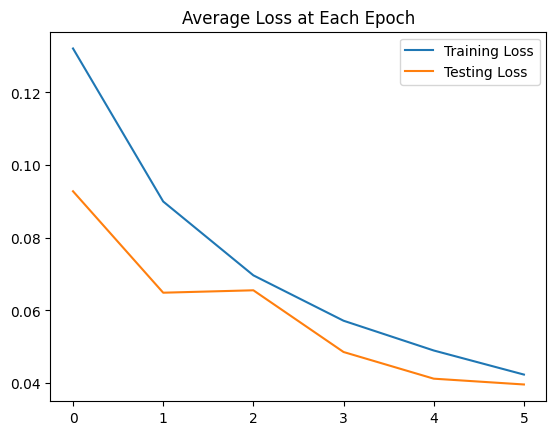

In [13]:
#Graph of results for CNN


#Training & Testing Data Graph
plt.plot(Loss_train, label="Training Loss")
plt.plot(Loss_test, label="Testing Loss")
plt.title("Average Loss at Each Epoch")
plt.legend()




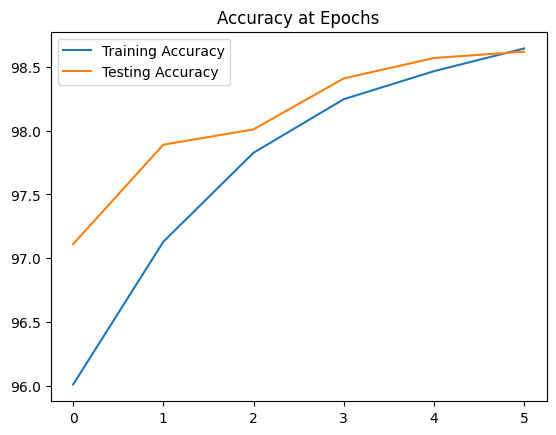

In [14]:
# Graph of accuracy @ end of each Epoch

plt.plot([t/600 for t in Correct_train], label="Training Accuracy")
plt.plot([t/100 for t in Correct_test], label="Testing Accuracy")
plt.title("Accuracy at Epochs")
plt.legend()







In [15]:
# Load All of Testing Data to Get number correct

test_load_All = DataLoader(test_data, batch_size=10000, shuffle=False)





In [16]:
# Run Evaluation of All Test Data

with torch.no_grad():
  correct = 0
  for X_test, y_test in test_load_All:

    y_val = model(X_test)

    prediction = torch.max(y_val, 1)[1]

    correct += (prediction == y_test).sum()




In [17]:
# Number correct
correct.item()



9862

In [18]:
# Accuracy calculation
correct.item()/len(test_data)*100



98.61999999999999

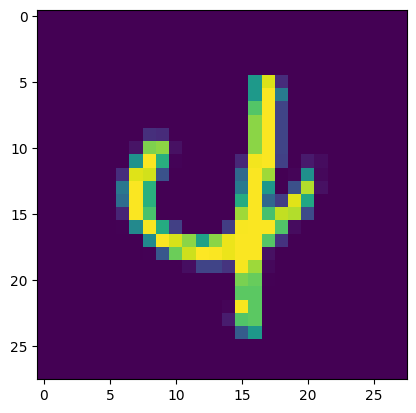

In [19]:
# Load and evaluate a single image

# Show image
plt.imshow(test_data[1300][0].reshape(28,28))



In [20]:
#Pass image through model
model.eval()
with torch.no_grad():
  guess_image = model(test_data[1300][0].view(1, 1, 28, 28)) # Batch size of 1, 1 color channel, 28x28 image size
# Only want 0 index so label [4] is dropped

guess_image.argmax()


tensor(4)